# NN_L6_sentiment_models

**Test macro-F1 of seven text representations and classifiers on the Financial PhraseBank (5 random splits) and on finance tweets (3 seeds).**

Neural Networks and Deep Learning (NN), Lecture 6 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L6/NN_L6_sentiment_models/NN_L6_sentiment_models.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Macro-F1 = mean of the F1 scores of the three classes; bars are means, whiskers standard deviations.

pb tfidf_lr macro-F1 (%) = 73.49   [sent.pb.tfidf_lr.f1]
pb embbag_w2v macro-F1 (%) = 69.93   [sent.pb.embbag_w2v.f1]
tw tfidf_lr macro-F1 (%) = 75.47   [sent.tw.tfidf_lr.f1]
tw embbag_w2v macro-F1 (%) = 72.76   [sent.tw.embbag_w2v.f1]


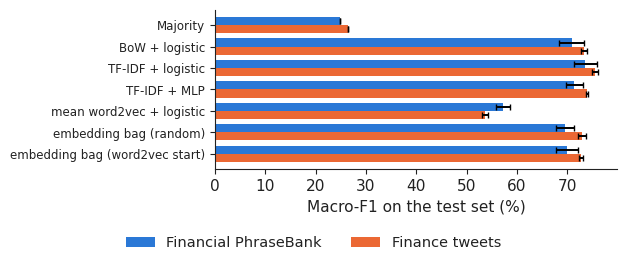

In [3]:
import json, urllib.request
_F = 'sentiment_models_results.json'
R = json.load(open(_F)) if os.path.isfile(_F) else json.load(urllib.request.urlopen(REPO + 'Quantlets/L6/NN_L6_sentiment_models/' + _F))
M = ['majority', 'bow_lr', 'tfidf_lr', 'tfidf_mlp', 'w2v_lr', 'embbag', 'embbag_w2v']
NAME = ['Majority', 'BoW + logistic', 'TF-IDF + logistic', 'TF-IDF + MLP', 'mean word2vec + logistic', 'embedding bag (random)', 'embedding bag (word2vec start)']
for ds in ['pb', 'tw']:
    for k in ['tfidf_lr', 'embbag_w2v']: show(f'sent.{ds}.{k}.f1', f'{ds} {k} macro-F1 (%)', round(float(np.mean(np.array(R[ds][k]['f1']) * 100)), 2))
fig, ax = plt.subplots(figsize=(6.4, 2.7)); y = np.arange(len(M))
for j, (ds, c, l) in enumerate([('pb', PAL['data'], 'Financial PhraseBank'), ('tw', PAL['model'], 'Finance tweets')]):
    ax.barh(y + (j - .5) * .38, [100 * np.mean(R[ds][k]['f1']) for k in M], height=.38, xerr=[100 * np.std(R[ds][k]['f1'], ddof=1) for k in M], color=c, capsize=2, label=l)
ax.set_yticks(y); ax.set_yticklabels(NAME, fontsize=8.5); ax.invert_yaxis(); ax.set_xlabel('Macro-F1 on the test set (%)'); legend_bottom(fig, ncol=2); fig.tight_layout(rect=(0, .12, 1, 1))
fig.savefig('sentiment_models.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()